In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import imdb
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
# Q1a) hyperparameters
num_words = 10000     # TODO (Q1a): keep the 10000 most frequent words
maxlen    = 200     # TODO (Q1a): fix every review to 200 tokens

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=num_words)

# Q1b) pad both sets to a fixed length
X_train = pad_sequences(X_train, maxlen=maxlen)   # TODO (Q1b): maxlen
X_test  = pad_sequences(X_test,  maxlen=maxlen)   # TODO (Q1b): maxlen

# Q1c) hold out 20% of training data for validation
X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.2, random_state=42)   # TODO (Q1c): 0.2

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
X_train: (20000, 200)  X_val: (5000, 200)  X_test: (25000, 200)


In [3]:
assert X_train.shape[1] == 200, "reviews should be padded to length 200"
assert set(np.unique(y_train)) <= {0, 1}, "labels should be binary (0/1)"
print("Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000, 200)")

Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000, 200)


In [4]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding: vocabulary size -> 128-dim word vectors
model.add(Embedding(input_dim=num_words, output_dim=128))   # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM with 64 units, returning ONE summary vector
model.add(Bidirectional(LSTM(64, return_sequences=False)))   # TODO (Q2b): 64, False

# Q2c) Dropout to reduce overfitting
model.add(Dropout(0.5))   # TODO (Q2c): 0.5

# Q2d) Output: one neuron, sigmoid (positive/negative probability)
model.add(Dense(1, activation='sigmoid'))   # TODO (Q2d): 1, 'sigmoid'

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,378,945 (5.26 MB)

 Trainable params: 1,378,945 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# Q3a) compile for binary classification
model.compile(optimizer='adam',
              loss='binary_crossentropy',              # TODO (Q3a): 'binary_crossentropy'
              metrics=['accuracy'])

# Q3b) train
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=5,          # TODO (Q3b): 5
                    batch_size=64)      # TODO (Q3b): 64

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.7469 - loss: 0.5047 - val_accuracy: 0.8316 - val_loss: 0.3931
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step - accuracy: 0.8903 - loss: 0.2836 - val_accuracy: 0.8718 - val_loss: 0.3095
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 22ms/step - accuracy: 0.9263 - loss: 0.2049 - val_accuracy: 0.8686 - val_loss: 0.3176
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 26ms/step - accuracy: 0.9456 - loss: 0.1540 - val_accuracy: 0.8694 - val_loss: 0.3627
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 8s 25ms/step - accuracy: 0.9232 - loss: 0.1862 - val_accuracy: 0.8104 - val_loss: 0.4397


782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8072 - loss: 0.4433
Test accuracy: 80.72%


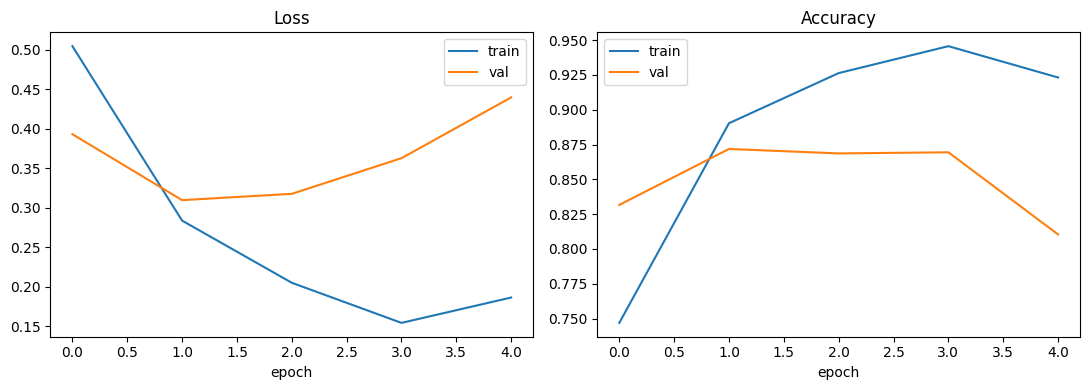

In [8]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~ 86-88%

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')      # TODO (Q4a): 'val_loss'
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')      # TODO (Q4b): 'val_accuracy'
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()

In [9]:
word_index = imdb.get_word_index()

def predict_sentiment(review):
    enc = [word_index.get(w, 0) + 3 for w in review.lower().split()]
    padded = pad_sequences([enc], maxlen=maxlen)
    p = model.predict(padded, verbose=0)[0][0]
    # Q5) threshold the sigmoid at 0.5
    return "Positive" if p >= 0.5 else "Negative"   # TODO (Q5): 0.5

for r in ["this film was absolutely wonderful and moving",
          "a boring dull waste of time"]:
    print(f"{predict_sentiment(r):8s} <- {r}")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Negative <- this film was absolutely wonderful and moving
Negative <- a boring dull waste of time


## Task 6 — Short questions *(write answers here)*

1. Why do we **pad** every review to the same length?
2. What does the **Embedding** layer do that one-hot encoding of words would not?
3. Why `return_sequences=False` here (unlike the music lab)?
4. Why `sigmoid` + `binary_crossentropy` instead of `softmax` + `categorical_crossentropy`?
5. In your accuracy plot, does validation loss start rising? What does that indicate, and what
   does `Dropout(0.5)` do about it?

> **Your answers:**
> 1. **Padding** is required because neural networks process inputs in uniform tensor shapes (batches). Since raw movie reviews vary in word count, padding them to a fixed length ensures consistent input dimensions (`200` tokens) for parallel GPU/CPU computations.
> 2. An **Embedding** layer maps high-dimensional, sparse, orthogonal one-hot vectors into a dense, low-dimensional space (e.g., 128 dimensions). Crucially, embeddings learn semantic relationships, meaning words with similar meanings end up closer to each other in this continuous vector space.
> 3. We use `return_sequences=False` because sentiment analysis is a **many-to-one** sequence classification task. We only need the final hidden state (a single summary vector) of the LSTM after reading the entire review to make a prediction, rather than step-by-step sequence predictions (which would be many-to-many).
> 4. We are performing **binary classification** (positive vs. negative) using a single output node. `sigmoid` outputs a single probability between 0 and 1, which works perfectly with `binary_crossentropy`. `softmax` and `categorical_crossentropy` are mathematically formulated to work with multiple outputs representing mutually exclusive classes.
> 5. **Yes**, around epoch 3, the validation loss begins to rise while training loss continues to decrease. This gap is a clear indicator of **overfitting**, where the model memorizes the training patterns. **`Dropout(0.5)`** mitigates this by randomly setting 50% of the activation inputs to 0 at each step during training, which prevents the network units from over-relying (co-adapting) on specific features, forcing it to learn more robust representations.